# CYB-5 — MiniLM Contextual Embeddings + Logistic Regression
**CPU/GPU notebook · Template-separated phishing evaluation**

This notebook compares a **frozen pretrained MiniLM encoder** with the existing TF-IDF baseline. MiniLM is a contextual *embedding model*, **not a generative LLM**. It is trained here only through the downstream logistic-regression classifier.

**Data (already prepared locally):** `train.parquet` (1,307), `validation.parquet` (277), `test.parquet` (316), and `original_exploratory.parquet` (100). The generated train/validation/test sets have nonoverlapping `template_id` values. The original 100 emails and held-out synthetic test templates have already been examined in earlier CYB-5 work, so all results in this notebook are **exploratory**, not a new blind evaluation.

Run cells from top to bottom. In Colab choose **Runtime → Change runtime type → T4 GPU** if available. In VS Code select the kernel that actually points to the desired runtime. A local kernel does not get Colab GPU resources automatically.

## 1 — Install dependencies

In [20]:
%pip -q install sentence-transformers scikit-learn pandas pyarrow joblib matplotlib

In [21]:

from sentence_transformers import SentenceTransformer

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device="cuda"
)

print("MiniLM loaded successfully!")
print("Embedding dimensions:", model.get_sentence_embedding_dimension())
print("Device:", model.device)
print("Maximum sequence length:", model.max_seq_length)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

MiniLM loaded successfully!
Embedding dimensions: 384
Device: cuda:0
Maximum sequence length: 256


/tmp/ipykernel_1902/2487600797.py:9: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embedding dimensions:", model.get_sentence_embedding_dimension())


## 2 — Check runtime and create output directories

In [22]:
from pathlib import Path
import os, sys, json, time, hashlib, random, shutil, zipfile
import numpy as np
import pandas as pd
import torch
import joblib
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import normalize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if DEVICE == 'cuda':
    torch.cuda.manual_seed_all(SEED)
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('GPU available:', torch.cuda.is_available())
print('Selected device:', DEVICE)
if DEVICE == 'cuda': print('GPU:', torch.cuda.get_device_name(0))

OUTPUT = Path.cwd() / 'cyb5_minilm_results'
OUTPUT.mkdir(parents=True, exist_ok=True)


Python: 3.13.16
PyTorch: 2.14.1+cu130
GPU available: True
Selected device: cuda
GPU: Tesla T4


## 3 — Locate or upload the four Parquet files
**In Google Colab:** run the cell and upload the four files from `D:\CYB5\data\phishing_validation\processed` when prompted. In **local VS Code/Jupyter**, files are found automatically if that directory exists; otherwise the upload prompt is only available in Colab.

Files contain email content; only upload data to services you are authorized to use. Do not publish raw emails or unreviewed embeddings.

In [23]:

from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

print("Google Drive mounted:", drive_root.exists())

if drive_root.exists():
    print("\nFolders and files in MyDrive:")
    for item in drive_root.iterdir():
        print("📁" if item.is_dir() else "📄", item.name)

    cyb5 = drive_root / "CYB5"
    if cyb5.exists():
        print("\nContents of CYB5:")
        for item in cyb5.iterdir():
            print("📁" if item.is_dir() else "📄", item.name)


Google Drive mounted: True

Folders and files in MyDrive:
📄 Untitled document (1).gdoc
📄 Cc template .gdoc
📄 CV (1).gdoc
📄 CV.gdoc
📄 CV_2024-07-21_Wijdane_AARROUB (1).pdf
📄 CIN (1).pdf
📄 CIN.pdf
📄 BAC (1).pdf
📄 BAC.pdf
📄 IMG_20240727_021038.jpg
📄 Adobe Scan Oct 23, 2023 (1)_1.jpg
📄 Adobe Scan Oct 23, 2023 (1)_2.jpg
📄 Adobe Scan May 16, 2022_1.jpg
📄 Adobe Scan May 16, 2022_2.jpg
📄 Adobe Scan Aug 14, 2022 (2).pdf
📄 DOC-20240727-WA0015..pdf
📄 Adobe Scan Jul 31, 2024 (2).pdf
📄 Adobe Scan Aug 02, 2024.pdf
📄 Adobe Scan Jul 31, 2024 (1)_1.jpg
📄 RELEVE DE NOTES 2EME (3).pdf
📄 RELEVE DE NOTES 2EME (2).pdf
📄 RELEVE DE NOTES 2EME (1).pdf
📄 RELEVE DE NOTES 2EME.pdf
📄 ATTESTATION DE REUSITE.pdf
📄 RELEVE DE NOTES 1ER (4).pdf
📄 RELEVE DE NOTES 1ER (3).pdf
📄 RELEVE DE NOTES 1ER (2).pdf
📄 RELEVE DE NOTES 1ER (1).pdf
📄 RELEVE DE NOTES 1ER.pdf
📄 BAC.jpg
📄 merged (2).pdf
📄 RELEVE DE NOTES BAC.pdf
📄 RELEVE 1+2 ANNEE (1).pdf
📄 RELEVE 1+2 ANNEE.pdf
📄 CINRECTO.jpg
📄 CINVERSO.jpg
📄 PHOTO.jpg
📄 BACVERSO.jpg
📄 D

In [24]:

from pathlib import Path
from google.colab import drive

# Connect Google Drive
drive.mount("/content/drive")

# Folder containing the four datasets
DATA_DIR = Path("/content/drive/MyDrive/CYB5")

FILES = [
    "train.parquet",
    "validation.parquet",
    "test.parquet",
    "original_exploratory.parquet"
]

print("=== CYB-5 DATASET VERIFICATION ===")

missing = [
    filename
    for filename in FILES
    if not (DATA_DIR / filename).is_file()
]

if missing:
    raise FileNotFoundError(
        f"Missing files in {DATA_DIR}: {missing}"
    )

for filename in FILES:
    filepath = DATA_DIR / filename
    print(f"{filename}: {filepath.stat().st_size:,} bytes")

print("\nAll four datasets found!")
print("Dataset directory:", DATA_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
=== CYB-5 DATASET VERIFICATION ===
train.parquet: 167,176 bytes
validation.parquet: 36,646 bytes
test.parquet: 41,326 bytes
original_exploratory.parquet: 14,211 bytes

All four datasets found!
Dataset directory: /content/drive/MyDrive/CYB5


## 4 — Verify splits, labels, metadata and data integrity

In [25]:
sets = {k: pd.read_parquet(DATA_DIR / f'{k}.parquet') for k in ['train','validation','test','original_exploratory']}
required = {'text','label','template_id','text_hash'}
for name, df in sets.items():
    if not required.issubset(df.columns):
        raise ValueError(f'{name}: missing {required - set(df.columns)}')
    if df[list(required)].isna().any().any():
        raise ValueError(f'{name}: missing required values')
    if not set(df['label'].astype(int).unique()).issubset({0,1}):
        raise ValueError(f'{name}: unexpected label')
    if df['text_hash'].duplicated().any():
        raise ValueError(f'{name}: duplicate hash')
    print(f'{name:23} rows={len(df):4}  safe={(df.label==0).sum():4}  phishing={(df.label==1).sum():4}  templates={df.template_id.nunique()}')

for a, b in [('train','validation'),('train','test'),('validation','test')]:
    if not set(sets[a].template_id).isdisjoint(sets[b].template_id):
        raise ValueError(f'Template overlap: {a}/{b}')
for i,a in enumerate(sets):
    for b in list(sets)[i+1:]:
        if not set(sets[a].text_hash).isdisjoint(sets[b].text_hash):
            raise ValueError(f'Exact text overlap: {a}/{b}')
print('Verified: disjoint generated templates and pairwise nonoverlapping text hashes.')

train                   rows=1307  safe= 632  phishing= 675  templates=36
validation              rows= 277  safe= 134  phishing= 143  templates=8
test                    rows= 316  safe= 157  phishing= 159  templates=8
original_exploratory    rows= 100  safe=  77  phishing=  23  templates=1
Verified: disjoint generated templates and pairwise nonoverlapping text hashes.


## 5 — Load MiniLM and examine truncation
The public `all-MiniLM-L6-v2` encoder normally uses **256 tokens maximum**. Text beyond that is truncated, so we report how often this happens. The encoder is frozen; no email data is sent to a third-party inference API by this notebook (model weights download from Hugging Face).

In [26]:
from sentence_transformers import SentenceTransformer
MODEL_NAME = 'sentence-transformers/all-MiniLM-L6-v2'
encoder = SentenceTransformer(MODEL_NAME, device=DEVICE)
max_tokens = int(encoder.max_seq_length)
embedding_dim = int(encoder.get_sentence_embedding_dimension())
print('Model:', MODEL_NAME)
print('Max sequence tokens:', max_tokens)
print('Embedding dimensions:', embedding_dim)

def token_stats(df, name):
    # For a small corpus, direct token length calculation is acceptable.
    lengths = [len(ids) for ids in encoder.tokenizer(
        df['text'].astype(str).tolist(), add_special_tokens=True,
        truncation=False, padding=False)['input_ids']]
    return {'split':name,'samples':len(lengths),'mean_tokens':round(float(np.mean(lengths)),1),
            'max_tokens':int(np.max(lengths)),'over_limit':int(np.sum(np.array(lengths)>max_tokens)),
            'over_limit_pct':round(float(np.mean(np.array(lengths)>max_tokens))*100,2)}
truncation_table = pd.DataFrame([token_stats(df, k) for k,df in sets.items()])
display(truncation_table)
truncation_table.to_csv(OUTPUT/'truncation_summary.csv', index=False)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

/tmp/ipykernel_1902/2496927951.py:5: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  embedding_dim = int(encoder.get_sentence_embedding_dimension())


Model: sentence-transformers/all-MiniLM-L6-v2
Max sequence tokens: 256
Embedding dimensions: 384


,split,samples,mean_tokens,max_tokens,over_limit,over_limit_pct
0,train,1307,42.4,57,0,0.0
1,validation,277,43.7,54,0,0.0
2,test,316,42.5,58,0,0.0
3,original_exploratory,100,20.9,25,0,0.0


## 6 — Encode emails with MiniLM
This encodes train, validation, test and exploratory original emails **without fitting MiniLM**. Set a smaller `BATCH_SIZE` if you run out of GPU/CPU memory. For reproducibility, we cache only arrays locally in the notebook environment.

In [27]:
BATCH_SIZE = 32 if DEVICE == 'cuda' else 16
embeddings = {}
for name, df in sets.items():
    start = time.perf_counter()
    X = encoder.encode(df['text'].astype(str).tolist(),
                       batch_size=BATCH_SIZE, show_progress_bar=True,
                       convert_to_numpy=True, normalize_embeddings=True)
    embeddings[name] = X.astype(np.float32)
    elapsed = time.perf_counter() - start
    print(f'{name:23}: {X.shape} | {elapsed:.1f}s | {len(df)/max(elapsed,1e-6):.1f} emails/s')


Batches:   0%|          | 0/41 [00:00<?, ?it/s]

train                  : (1307, 384) | 1.5s | 852.0 emails/s


Batches:   0%|          | 0/9 [00:00<?, ?it/s]

validation             : (277, 384) | 0.2s | 1701.8 emails/s


Batches:   0%|          | 0/10 [00:00<?, ?it/s]

test                   : (316, 384) | 0.2s | 1725.5 emails/s


Batches:   0%|          | 0/4 [00:00<?, ?it/s]

original_exploratory   : (100, 384) | 0.1s | 1391.2 emails/s


## 7 — Train Logistic Regression only on training embeddings

In [28]:
X_train = embeddings['train']
y_train = sets['train']['label'].astype(int).to_numpy()
clf = LogisticRegression(solver='liblinear', max_iter=2000, random_state=SEED)
clf.fit(X_train, y_train)
print('Downstream Logistic Regression trained on', X_train.shape, 'embeddings.')

Downstream Logistic Regression trained on (1307, 384) embeddings.


## 8 — Choose threshold using validation **only**
We maximize F1 over a fixed threshold grid on the existing validation partition. This is a baseline evaluation choice, not a guarantee of acceptable false-positive rate.

In [29]:
from sklearn.metrics import f1_score
val_y = sets['validation']['label'].astype(int).to_numpy()
val_p = clf.predict_proba(embeddings['validation'])[:, 1]
threshold_rows = []
for t in np.round(np.arange(0.10,0.901,0.01),2):
    pred = (val_p >= t).astype(int)
    cm = confusion_matrix(val_y, pred, labels=[0,1])
    tn, fp, fn, tp = cm.ravel()
    threshold_rows.append({'threshold':float(t), 'f1':float(f1_score(val_y,pred,zero_division=0)),
                           'fpr':float(fp/(fp+tn)) if fp+tn else np.nan})
threshold_df = pd.DataFrame(threshold_rows)
choice = threshold_df.assign(distance=(threshold_df.threshold-0.5).abs()).sort_values(
    ['f1','distance','threshold'], ascending=[False,True,True]).iloc[0]
THRESHOLD = float(choice.threshold)
print('Validation-selected threshold:', THRESHOLD)
print('Validation F1:', round(float(choice.f1),4))
print('Validation FPR:', round(float(choice.fpr),4))
threshold_df.to_csv(OUTPUT/'validation_threshold_grid.csv',index=False)

Validation-selected threshold: 0.2
Validation F1: 0.993
Validation FPR: 0.0075


## 9 — Evaluate all splits at that frozen threshold
The generated `test` set and `original_exploratory` records were previously examined in CYB-5. Treat these as **exploratory comparisons**, not untouched final validation.

,split,n,accuracy,precision,recall,f1,fpr,tn,fp,fn,tp
0,train,1307,0.9572,0.9234,1.000,0.9602,0.0886,576,56,0,675
1,validation,277,0.9928,0.9930,0.993,0.9930,0.0075,133,1,1,142
2,test,316,0.8703,0.7950,1.000,0.8858,0.2611,116,41,0,159
3,original_exploratory,100,0.8000,0.5349,1.000,0.6970,0.2597,57,20,0,23



UNSEEN TEMPLATE TEST CLASSIFICATION REPORT
              precision    recall  f1-score   support

        Safe       1.00      0.74      0.85       157
    Phishing       0.80      1.00      0.89       159

    accuracy                           0.87       316
   macro avg       0.90      0.87      0.87       316
weighted avg       0.90      0.87      0.87       316



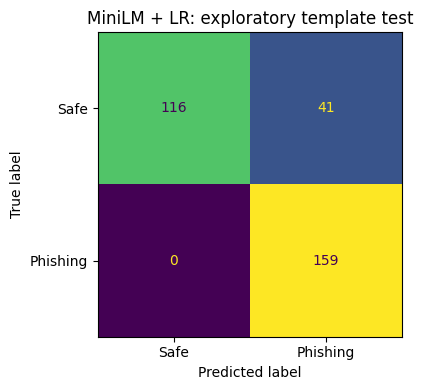

In [30]:
def report(name):
    y = sets[name].label.astype(int).to_numpy()
    p = clf.predict_proba(embeddings[name])[:,1]
    pred = (p>=THRESHOLD).astype(int)
    tn,fp,fn,tp = confusion_matrix(y,pred,labels=[0,1]).ravel()
    res = {'split':name,'n':int(len(y)),'accuracy':float(accuracy_score(y,pred)),
           'precision':float(precision_score(y,pred,zero_division=0)),
           'recall':float(recall_score(y,pred,zero_division=0)),
           'f1':float(f1_score(y,pred,zero_division=0)),
           'fpr':float(fp/(fp+tn)) if fp+tn else None,
           'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)}
    return res, y, pred
reports = {}
for split in ['train','validation','test','original_exploratory']:
    reports[split], _, _ = report(split)
results_table = pd.DataFrame(list(reports.values()))
display(results_table.round(4))
results_table.to_csv(OUTPUT/'minilm_metrics.csv', index=False)
(OUTPUT/'minilm_metrics.json').write_text(json.dumps({'model':MODEL_NAME,'max_seq_length':max_tokens,
    'embedding_dim':embedding_dim,'device':DEVICE,'threshold_selected_on':'validation',
    'threshold':THRESHOLD,'metrics':reports,
    'limitations':['generated template data','exploratory test previously inspected',
                   'original_v1 subset previously inspected','encoder truncates longer emails']}, indent=2),encoding='utf-8')
_, y_test, pred_test = report('test')
print('\nUNSEEN TEMPLATE TEST CLASSIFICATION REPORT')
print(classification_report(y_test,pred_test,labels=[0,1],target_names=['Safe','Phishing'],zero_division=0))
fig, ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(confusion_matrix(y_test,pred_test,labels=[0,1]),display_labels=['Safe','Phishing']).plot(ax=ax,values_format='d',colorbar=False)
ax.set_title('MiniLM + LR: exploratory template test')
fig.tight_layout()
fig.savefig(OUTPUT/'minilm_test_confusion_matrix.png', dpi=160)
plt.show()

## 10 — Diagnostic by held-out template
Do **not** use this diagnostic to retune the threshold on the test set. The results describe template sensitivity only.

In [31]:
test = sets['test'].copy()
test['prediction'] = pred_test
test['score'] = clf.predict_proba(embeddings['test'])[:,1]
template_report = test.groupby(['template_id','label']).agg(
    n=('label','size'), accuracy=('prediction',lambda x:float((x==test.loc[x.index,'label']).mean())),
    mean_score=('score','mean')).reset_index()
display(template_report.sort_values('accuracy').round(4))
template_report.to_csv(OUTPUT/'minilm_by_template.csv',index=False)

,template_id,label,n,accuracy,mean_score
6,SAFE_ORDER_CONF,0,41,0.0,0.3617
0,PHISH_ACCT_LOGIN,1,42,1.0,0.9473
2,PHISH_PAY_DECLINE,1,38,1.0,0.9553
1,PHISH_ACCT_PWD,1,35,1.0,0.9525
3,PHISH_VISH_SUSP,1,44,1.0,0.9640
4,SAFE_AGENDA,0,35,1.0,0.0150
5,SAFE_ANNIV,0,40,1.0,0.0476
7,SAFE_WIKI_LINK,0,41,1.0,0.0108


## 11 — Optional: compare with the previously measured TF-IDF baseline
These are **recorded historical values** from your earlier template-separated experiment; they are not rerun here. Same partitions, but the test set was already inspected.

In [32]:
reference = {'model':'TF-IDF + Logistic Regression (prior run)','accuracy':0.8703,
             'precision':0.7950,'recall':1.0,'f1':0.8858,'fpr':0.2611}
current = reports['test']
comparison = pd.DataFrame([reference,{'model':'MiniLM embeddings + Logistic Regression',
  **{k:current[k] for k in ['accuracy','precision','recall','f1','fpr']}}])
display(comparison.round(4))
comparison.to_csv(OUTPUT/'minilm_vs_tfidf.csv', index=False)

,model,accuracy,precision,recall,f1,fpr
0,TF-IDF + Logistic Regression (prior run),0.8703,0.795,1.0,0.8858,0.2611
1,MiniLM embeddings + Logistic Regression,0.8703,0.795,1.0,0.8858,0.2611


## 12 — Save model, metadata, and download the results
The saved downstream classifier requires the **same MiniLM encoder** and `max_seq_length` to reproduce predictions. We do not package the raw email data. The output ZIP contains metrics, charts, threshold grid, and a small joblib classifier. Note that notebooks and metadata can still be sensitive in private research workflows.

In [33]:
joblib.dump(clf, OUTPUT/'minilm_logreg.joblib')
config = {'encoder':MODEL_NAME,'max_seq_length':max_tokens,'embedding_dim':embedding_dim,
          'threshold':THRESHOLD,'seed':SEED, 'train_size':len(sets['train']),
          'validation_size':len(sets['validation']), 'test_size':len(sets['test']),
          'method':'frozen sentence transformer embeddings + logistic regression',
          'train_only':'train.parquet','threshold_selection':'validation.parquet',
          'evaluation_warning':'test and original subsets have been inspected previously'}
(OUTPUT/'model_config.json').write_text(json.dumps(config, indent=2),encoding='utf-8')
archive = Path.cwd()/'CYB5_MiniLM_Results.zip'
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for file in sorted(OUTPUT.iterdir()):
        if file.is_file(): z.write(file, arcname=file.name)
print('Results folder:', OUTPUT)
print('ZIP saved:', archive)
try:
    from google.colab import files
    files.download(str(archive))
except ImportError:
    print('Running outside Colab: use your file explorer to retrieve the ZIP.')

Results folder: /content/cyb5_minilm_results
ZIP saved: /content/CYB5_MiniLM_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Screenshot checklist for the research report
- **Capture 50:** Device verification + MiniLM model dimensions and token limit
- **Capture 51:** Input truncation summary (show % emails above token limit)
- **Capture 52:** Selected validation threshold and metrics
- **Capture 53:** Held-out template test table and confusion matrix
- **Capture 54:** MiniLM vs TF-IDF comparison and per-template analysis

**Research caution:** All these results are exploratory because model and benchmark decisions have been made while examining evaluation data. For a publishable final result, obtain a new independently collected real-world phishing corpus with verified labels and reserve it untouched.

In [37]:

from pathlib import Path
import shutil

source = Path("/content/CYB5_MiniLM_Results.zip")
destination = Path("/content/drive/MyDrive/CYB5_MiniLM_Results.zip")

print("Source exists:", source.exists())
print("Google Drive mounted:", Path("/content/drive/MyDrive").exists())

if not source.is_file():
    raise FileNotFoundError("The results ZIP is missing from Colab.")

if not destination.parent.is_dir():
    raise FileNotFoundError("Google Drive is not mounted.")

shutil.copy2(source, destination)

print("COPY SUCCESSFUL!")
print("Saved file:", destination.name)
print("Size:", destination.stat().st_size, "bytes")


Source exists: True
Google Drive mounted: True
COPY SUCCESSFUL!
Saved file: CYB5_MiniLM_Results.zip
Size: 28361 bytes
